# Clasificación de cáncer de piel con ResNet-18

Este notebook transforma el script original en una versión más didáctica, comentada en español y organizada por bloques. El objetivo es entrenar una **ResNet-18 preentrenada en ImageNet** para clasificar imágenes de lesiones cutáneas en dos clases.

La idea central es aplicar **transfer learning**: se reutiliza una red ya entrenada sobre millones de imágenes y se sustituye su última capa para adaptarla al problema concreto de clasificación binaria.

Además, el notebook guarda resultados intermedios en disco: configuración, métricas por época, checkpoints del modelo, gráficas de entrenamiento y algunas predicciones de ejemplo.

## 1. Importación de librerías

Se importan las librerías necesarias para trabajar con imágenes, redes neuronales, entrenamiento, evaluación y visualización de resultados.

In [1]:
from pathlib import Path
import json
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch import nn
from torch.utils.data import DataLoader

import torchvision
from torchvision import transforms, datasets

## 2. Configuración general

Aquí se centralizan los principales hiperparámetros del experimento: rutas de datos, tamaño de imagen, tamaño de batch, número de épocas y tasa de aprendizaje.

La carpeta de datos debe seguir la estructura esperada por `ImageFolder`:

```text
03. skin_cancer/data/
├── train/
│   ├── clase_0/
│   └── clase_1/
└── test/
    ├── clase_0/
    └── clase_1/
```

In [2]:
# Rutas del dataset
TRAIN_DIR = Path("./03. skin_cancer/data/train/")
TEST_DIR = Path("./03. skin_cancer/data/test/")

# Carpeta donde se guardarán los resultados del experimento
OUTPUT_DIR = Path("./03. skin_cancer/resultados_resnet18")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hiperparámetros principales
IMAGE_SIZE = 224
BATCH_SIZE = 24
NUM_EPOCHS = 50
LEARNING_RATE = 0.7
STEP_SIZE = 2
GAMMA = 0.5
NUM_WORKERS = 8
SEED = 42

# Para reproducibilidad parcial
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Selección automática del dispositivo
# CUDA se usa en GPUs NVIDIA. MPS puede usarse en equipos Apple Silicon compatibles.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Dispositivo utilizado: {DEVICE}")

Dispositivo utilizado: cuda


## 3. Guardado de la configuración

Guardar la configuración permite saber con qué parámetros se entrenó el modelo. Esto es especialmente útil cuando se comparan varios experimentos.

In [3]:
config = {
    "train_dir": str(TRAIN_DIR),
    "test_dir": str(TEST_DIR),
    "output_dir": str(OUTPUT_DIR),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "num_epochs": NUM_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "step_size": STEP_SIZE,
    "gamma": GAMMA,
    "num_workers": NUM_WORKERS,
    "seed": SEED,
    "device": str(DEVICE),
}

with open(OUTPUT_DIR / "configuracion.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

config

{'train_dir': '03. skin_cancer\\data\\train',
 'test_dir': '03. skin_cancer\\data\\test',
 'output_dir': '03. skin_cancer\\resultados_resnet18',
 'image_size': 224,
 'batch_size': 24,
 'num_epochs': 50,
 'learning_rate': 0.7,
 'step_size': 2,
 'gamma': 0.5,
 'num_workers': 8,
 'seed': 42,
 'device': 'cuda'}

## 4. Transformaciones y aumento de datos

ResNet-18 espera imágenes de tamaño **224 × 224**. Además, cuando usamos modelos preentrenados en ImageNet, es habitual normalizar las imágenes con la media y desviación típica de ImageNet.

En entrenamiento se aplica **data augmentation** para mejorar la generalización del modelo. En validación/test no se introducen transformaciones aleatorias, porque queremos evaluar de forma estable.

In [4]:
# Transformaciones para entrenamiento: incluyen aumentos aleatorios de datos
transforms_train = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomResizedCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# Transformaciones para validación/test: deterministas, sin aleatoriedad
transforms_test = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.CenterCrop((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

## 5. Carga del dataset

`ImageFolder` asigna automáticamente una etiqueta numérica a cada carpeta. Por ejemplo, si existen dos carpetas, una para lesiones benignas y otra para malignas, cada una se convierte en una clase.

In [5]:
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=transforms_train)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=transforms_test)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print("Clases detectadas:", train_dataset.classes)
print("Índices de clase:", train_dataset.class_to_idx)
print("Número de imágenes de entrenamiento:", len(train_dataset))
print("Número de imágenes de test/validación:", len(test_dataset))

Clases detectadas: ['benign', 'malignant']
Índices de clase: {'benign': 0, 'malignant': 1}
Número de imágenes de entrenamiento: 2637
Número de imágenes de test/validación: 660


## 6. Visualización de imágenes de ejemplo

Antes de entrenar, conviene inspeccionar algunas imágenes. Como los tensores están normalizados, se define una función auxiliar para desnormalizarlos antes de mostrarlos.

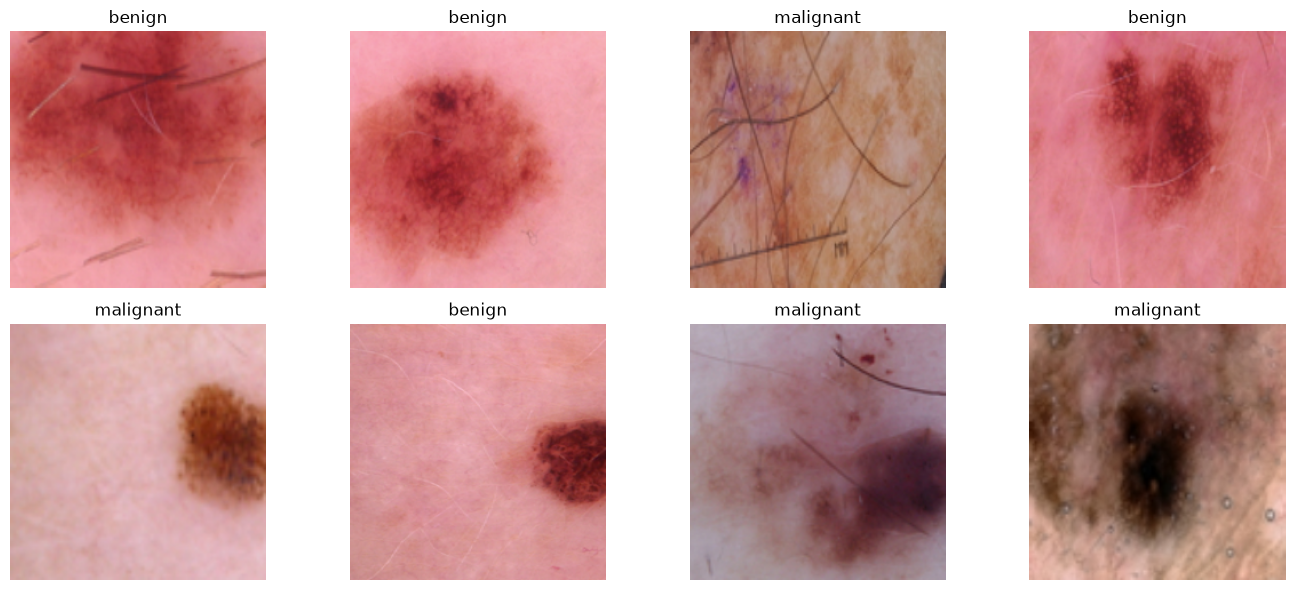

In [6]:
def denormalize_image(tensor):
    """Desnormaliza una imagen normalizada con la media y desviación típica de ImageNet."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = tensor.cpu() * std + mean
    image = torch.clamp(image, 0, 1)
    return image

# Tomamos un batch del dataloader de entrenamiento
images, labels = next(iter(train_dataloader))

num_images = min(8, images.size(0))
plt.figure(figsize=(14, 6))
for i in range(num_images):
    image = denormalize_image(images[i]).permute(1, 2, 0).numpy()
    label_name = train_dataset.classes[labels[i].item()]
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(label_name)
    plt.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ejemplos_dataset.png", dpi=150)
plt.show()

## 7. Definición del modelo ResNet-18

Se carga una **ResNet-18 preentrenada**. La red original termina con una capa lineal diseñada para las 1000 clases de ImageNet. Para este problema, sustituimos esa capa final por una nueva capa con tantas salidas como clases tenga nuestro dataset.

En este ejemplo se entrenan únicamente los parámetros de la capa final (`model.fc`). Esta estrategia es común cuando se quiere hacer una adaptación rápida con pocos datos.

In [7]:
# Cargamos ResNet-18 preentrenada.
# En versiones recientes de torchvision se recomienda usar weights en lugar de pretrained=True.
try:
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
    model = torchvision.models.resnet18(weights=weights)
except AttributeError:
    model = torchvision.models.resnet18(pretrained=True)

# Número de características que entran en la capa final original
num_features = model.fc.in_features
print("Número de características antes de la capa final:", num_features)

# Número de clases del dataset
num_classes = len(train_dataset.classes)

# Sustituimos la capa final por una nueva capa adaptada al problema
model.fc = nn.Linear(num_features, num_classes)

# Movemos el modelo al dispositivo disponible
model = model.to(DEVICE)

model

Número de características antes de la capa final: 512


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 8. Función de pérdida, optimizador y scheduler

Para clasificación multiclase se usa **CrossEntropyLoss**. Aunque el problema sea binario, esta función es adecuada cuando el modelo devuelve dos logits, uno por clase.

El optimizador se aplica solo a la última capa (`model.fc.parameters()`), por lo que el backbone preentrenado actúa como extractor de características.

In [8]:
criterion = nn.CrossEntropyLoss()

# Solo se optimizan los parámetros de la última capa
optimizer = torch.optim.Adadelta(model.fc.parameters(), lr=LEARNING_RATE)

# Reduce la tasa de aprendizaje cada STEP_SIZE épocas
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer=optimizer,
    step_size=STEP_SIZE,
    gamma=GAMMA,
)

## 9. Funciones auxiliares de entrenamiento y evaluación

Se separa el entrenamiento de una época y la evaluación para que el código sea más claro y reutilizable.

In [9]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    """Entrena el modelo durante una época."""
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels).item()

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_accuracy = running_corrects / len(dataloader.dataset) * 100
    return epoch_loss, epoch_accuracy


def evaluate(model, dataloader, criterion, device):
    """Evalúa el modelo sin actualizar pesos."""
    model.eval()
    running_loss = 0.0
    running_corrects = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels).item()

            all_labels.extend(labels.cpu().numpy().tolist())
            all_predictions.extend(preds.cpu().numpy().tolist())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_accuracy = running_corrects / len(dataloader.dataset) * 100
    return epoch_loss, epoch_accuracy, all_labels, all_predictions

## 10. Entrenamiento del modelo

Durante cada época se entrena el modelo y después se evalúa en el conjunto de test/validación. Se guardan métricas y checkpoints para poder recuperar el modelo posteriormente.

In [10]:
history = []
best_test_accuracy = 0.0
start_time = time.time()

for epoch in range(NUM_EPOCHS):
    print(f"Época {epoch + 1}/{NUM_EPOCHS}")

    train_loss, train_accuracy = train_one_epoch(
        model, train_dataloader, criterion, optimizer, DEVICE
    )

    test_loss, test_accuracy, y_true, y_pred = evaluate(
        model, test_dataloader, criterion, DEVICE
    )

    scheduler.step()

    elapsed_time = time.time() - start_time
    current_lr = scheduler.get_last_lr()[0]

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "learning_rate": current_lr,
        "elapsed_seconds": elapsed_time,
    }
    history.append(row)

    print(
        f"Entrenamiento | pérdida: {train_loss:.4f} | precisión: {train_accuracy:.2f}%"
        f"Validación    | pérdida: {test_loss:.4f} | precisión: {test_accuracy:.2f}%"
        f"Learning rate: {current_lr:.6f} | tiempo acumulado: {elapsed_time / 60:.2f} min"
    )

    # Guardamos checkpoint de cada época
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "class_to_idx": train_dataset.class_to_idx,
        "history": history,
    }
    torch.save(checkpoint, OUTPUT_DIR / f"checkpoint_epoch_{epoch + 1:03d}.pt")

    # Guardamos también el mejor modelo según accuracy de validación
    if test_accuracy > best_test_accuracy:
        best_test_accuracy = test_accuracy
        torch.save(checkpoint, OUTPUT_DIR / "mejor_modelo.pt")
        print("Nuevo mejor modelo guardado.")

    # Guardamos métricas acumuladas en CSV tras cada época
    pd.DataFrame(history).to_csv(OUTPUT_DIR / "metricas_entrenamiento.csv", index=False)
    print("-" * 70)

end_time = time.time()
print(f"Tiempo total de entrenamiento: {(end_time - start_time) / 60:.2f} minutos")

Época 1/50
Entrenamiento | pérdida: 0.5272 | precisión: 74.82%Validación    | pérdida: 0.4064 | precisión: 79.39%Learning rate: 0.700000 | tiempo acumulado: 0.76 min
Nuevo mejor modelo guardado.
----------------------------------------------------------------------
Época 2/50
Entrenamiento | pérdida: 0.4283 | precisión: 79.64%Validación    | pérdida: 0.5191 | precisión: 71.67%Learning rate: 0.350000 | tiempo acumulado: 1.64 min
----------------------------------------------------------------------
Época 3/50
Entrenamiento | pérdida: 0.3978 | precisión: 81.27%Validación    | pérdida: 0.3945 | precisión: 81.06%Learning rate: 0.350000 | tiempo acumulado: 2.42 min
Nuevo mejor modelo guardado.
----------------------------------------------------------------------
Época 4/50
Entrenamiento | pérdida: 0.3811 | precisión: 82.59%Validación    | pérdida: 0.5560 | precisión: 70.91%Learning rate: 0.175000 | tiempo acumulado: 3.05 min
-----------------------------------------------------------------

## 11. Curvas de entrenamiento

Las curvas de pérdida y precisión permiten analizar si el modelo está aprendiendo, si hay sobreajuste o si el entrenamiento necesita más épocas.

In [11]:
history_df = pd.DataFrame(history)
history_df

,epoch,train_loss,train_accuracy,test_loss,test_accuracy,learning_rate,elapsed_seconds
0,1,0.527160,74.819871,0.406431,79.393939,7.000000e-01,45.831937
1,2,0.428263,79.635950,0.519085,71.666667,3.500000e-01,98.160180
2,3,0.397797,81.266591,0.394495,81.060606,3.500000e-01,145.323663
3,4,0.381053,82.593857,0.556050,70.909091,1.750000e-01,182.925647
4,5,0.368442,83.314372,0.379307,81.818182,1.750000e-01,220.488281
5,6,0.371365,82.821388,0.369520,82.424242,8.750000e-02,264.016848
6,7,0.367644,83.048919,0.366609,83.484848,8.750000e-02,302.086366
7,8,0.367291,82.821388,0.368798,82.575758,4.375000e-02,339.750257
8,9,0.367144,82.821388,0.380865,81.666667,4.375000e-02,377.482636
9,10,0.373820,82.404247,0.372995,82.424242,2.187500e-02,415.509194


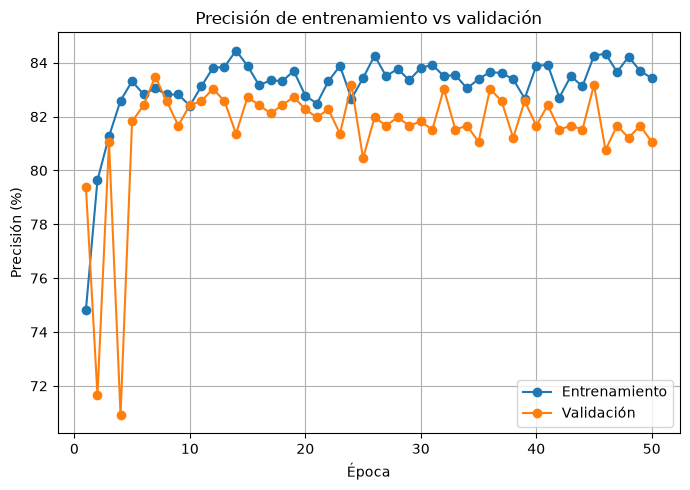

In [12]:
plt.figure(figsize=(7, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Entrenamiento")
plt.plot(history_df["epoch"], history_df["test_accuracy"], marker="o", label="Validación")
plt.xlabel("Época")
plt.ylabel("Precisión (%)")
plt.title("Precisión de entrenamiento vs validación")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "curva_precision.png", dpi=150)
plt.show()

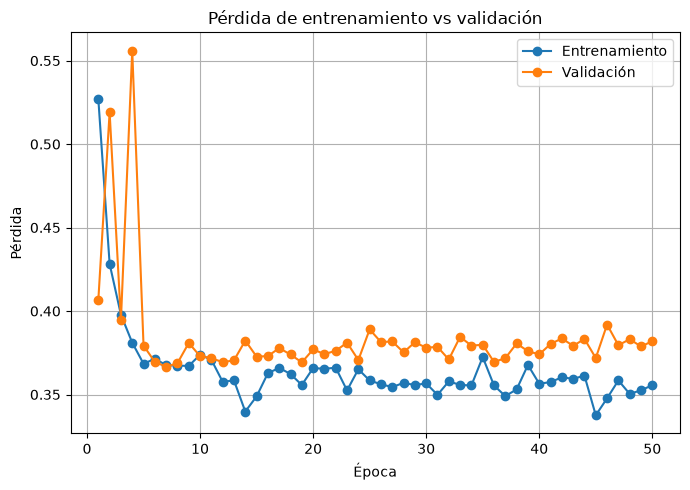

In [13]:
plt.figure(figsize=(7, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Entrenamiento")
plt.plot(history_df["epoch"], history_df["test_loss"], marker="o", label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida de entrenamiento vs validación")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "curva_perdida.png", dpi=150)
plt.show()

## 12. Predicciones de ejemplo

Finalmente, se visualizan algunas predicciones del modelo sobre imágenes del conjunto de test/validación.

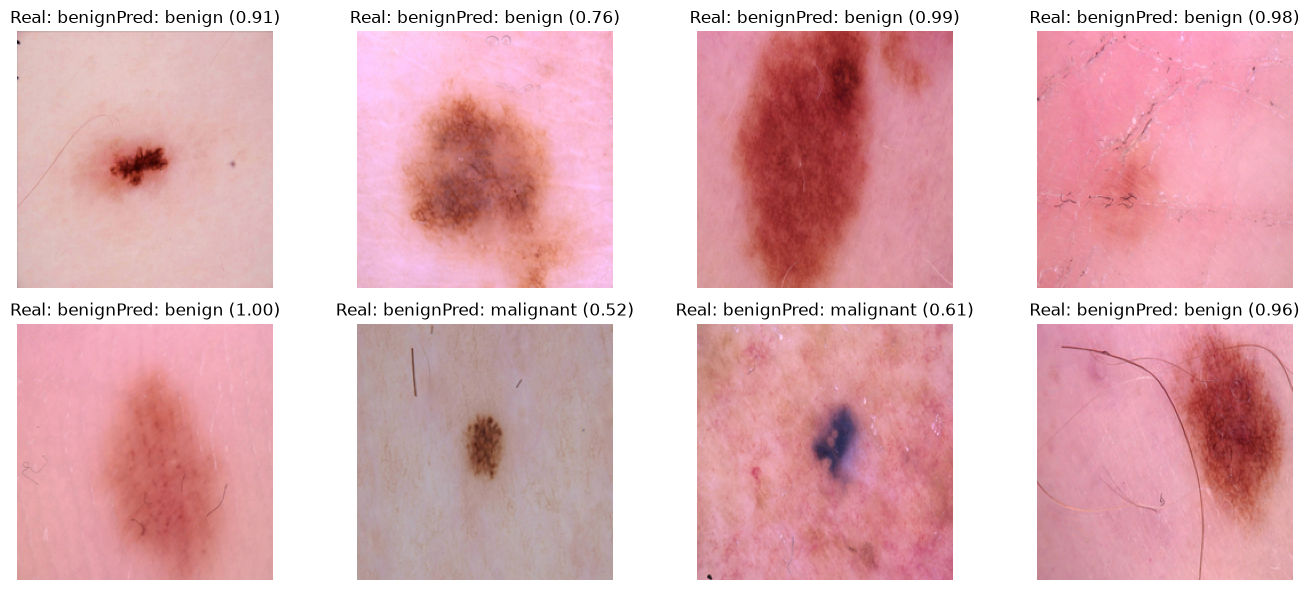

In [14]:
def predict_batch(model, dataloader, device):
    """Devuelve un batch con imágenes, etiquetas reales y predicciones."""
    model.eval()
    inputs, labels = next(iter(dataloader))
    inputs_device = inputs.to(device)

    with torch.no_grad():
        outputs = model(inputs_device)
        probabilities = torch.softmax(outputs, dim=1)
        confidences, preds = torch.max(probabilities, 1)

    return inputs, labels, preds.cpu(), confidences.cpu()

images, labels, preds, confidences = predict_batch(model, test_dataloader, DEVICE)

num_images = min(8, images.size(0))
plt.figure(figsize=(14, 6))
for i in range(num_images):
    image = denormalize_image(images[i]).permute(1, 2, 0).numpy()
    true_label = test_dataset.classes[labels[i].item()]
    predicted_label = test_dataset.classes[preds[i].item()]
    confidence = confidences[i].item()

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(f"Real: {true_label}Pred: {predicted_label} ({confidence:.2f})")
    plt.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "predicciones_ejemplo.png", dpi=150)
plt.show()

## 13. Guardado final del modelo

Se guarda el estado final del modelo, además del mejor checkpoint ya almacenado durante el entrenamiento.

In [15]:
final_checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "classes": train_dataset.classes,
    "history": history,
    "config": config,
}

torch.save(final_checkpoint, OUTPUT_DIR / "modelo_final.pt")

print("Modelo final guardado en:", OUTPUT_DIR / "modelo_final.pt")
print("Mejor modelo guardado en:", OUTPUT_DIR / "mejor_modelo.pt")
print("Métricas guardadas en:", OUTPUT_DIR / "metricas_entrenamiento.csv")

Modelo final guardado en: 03. skin_cancer\resultados_resnet18\modelo_final.pt
Mejor modelo guardado en: 03. skin_cancer\resultados_resnet18\mejor_modelo.pt
Métricas guardadas en: 03. skin_cancer\resultados_resnet18\metricas_entrenamiento.csv


## 14. Comentario final

Este notebook ilustra una estrategia clásica de **transfer learning**: usar una red profunda preentrenada como extractor de características y entrenar una nueva capa final para el problema específico.

En una aplicación médica real, este flujo debería ampliarse con validación cruzada, balanceo de clases, métricas clínicas como sensibilidad y especificidad, análisis de falsos negativos, explicabilidad visual y una evaluación externa sobre datos no vistos.